# Noun Phrase (NP) Chunking with a Hidden Markov Model

**Task.** Tag every word of a sentence as `B-NP` (begins a noun phrase), `I-NP` (inside a noun phrase) or `O` (outside).

**Model.** A first-order HMM, estimated by counting from the training data:

| Symbol | Meaning | Estimate (Add-K) |
|---|---|---|
| π(t) | P(first tag = t) | (C(start→t) + K) / (N_sent + K·\|T\|) |
| A(t′ \| t) | P(next tag = t′ \| tag = t) | (C(t→t′) + K) / (C(t) + K·\|T\|) |
| B(w \| t) | P(word = w \| tag = t) | (C(t,w) + K) / (C(t) + K·(\|V\|+1)) |

The extra `+1` in the emission denominator is an `<UNK>` slot, so words never seen in training still receive a small, non‑zero probability.

**Algorithms**
* **Forward** – P(w₁…wₙ) = Σ over *all* tag sequences of π·A·B. Recursion: α₁(j)=π(j)B(w₁\|j),  α_t(j)=Σᵢ α_{t−1}(i)·A(j\|i)·B(w_t\|j).
* **Viterbi** – the single most probable tag sequence. Same recursion with `max` instead of `Σ`, plus back‑pointers.

All computations run in **log space** (`logsumexp` for the forward algorithm) to avoid numerical underflow.

**Notebook outline**
1. Load data  2. Exploratory analysis  3. Estimate HMM (+ choose K on a dev split)  4. Forward algorithm (worked example, brute‑force check, all test sentences)  5. Viterbi (worked example, all test sentences)  6. Evaluation with `seqeval` + confusion matrix + error analysis  7. Sensitivity to K  8. Save results

In [3]:
# !pip install seqeval matplotlib pandas scipy
import itertools, math
import numpy as np, pandas as pd
import matplotlib.pyplot as plt
from collections import Counter, defaultdict
from scipy.special import logsumexp
from seqeval.metrics import classification_report, f1_score, precision_score, recall_score, accuracy_score

plt.rcParams.update({'figure.dpi': 110, 'axes.grid': True, 'grid.alpha': .25, 'axes.spines.top': False, 'axes.spines.right': False})
pd.set_option('display.width', 160); pd.set_option('display.max_colwidth', 80)

TRAIN_PATH = '/Users/mjgandhi2305/Semester_7/ILLM/Lab7/Data/test_NP.txt'   # adjust if the files live elsewhere
TEST_PATH  = '/Users/mjgandhi2305/Semester_7/ILLM/Lab7/Data/test_NP.txt'

## 1. Load data
Format: one `word<TAB>tag` per line, sentences separated by a blank line.

In [9]:
def read_data(path):
    sents, words, tags = [], [], []
    with open(path, encoding='utf-8') as f:
        for line in f:
            line = line.rstrip('\n')
            if not line.strip():
                if words: sents.append((words, tags)); words, tags = [], []
                continue
            parts = line.split()
            words.append(parts[0]); tags.append(parts[-1])
    if words: sents.append((words, tags))
    return sents

train = read_data(TRAIN_PATH)
test  = read_data(TEST_PATH)
print(f'train: {len(train)} sentences, {sum(len(w) for w,_ in train)} tokens')
print(f'test : {len(test)} sentences, {sum(len(w) for w,_ in test)} tokens')
print('\nFirst training sentence:')
print(' '.join(f'{w}/{t}' for w,t in zip(*train[0])))

train: 77 sentences, 1896 tokens
test : 77 sentences, 1896 tokens

First training sentence:
Confidence/B-NP in/O the/B-NP pound/I-NP is/O widely/O expected/O to/O take/O another/B-NP sharp/I-NP dive/I-NP if/O trade/B-NP figures/I-NP for/O September/B-NP ,/O due/O for/O release/B-NP tomorrow/B-NP ,/O fail/O to/O show/O a/B-NP substantial/I-NP improvement/I-NP from/O July/B-NP and/I-NP August/I-NP 's/B-NP near-record/I-NP deficits/I-NP ./O


## 2. Exploratory analysis

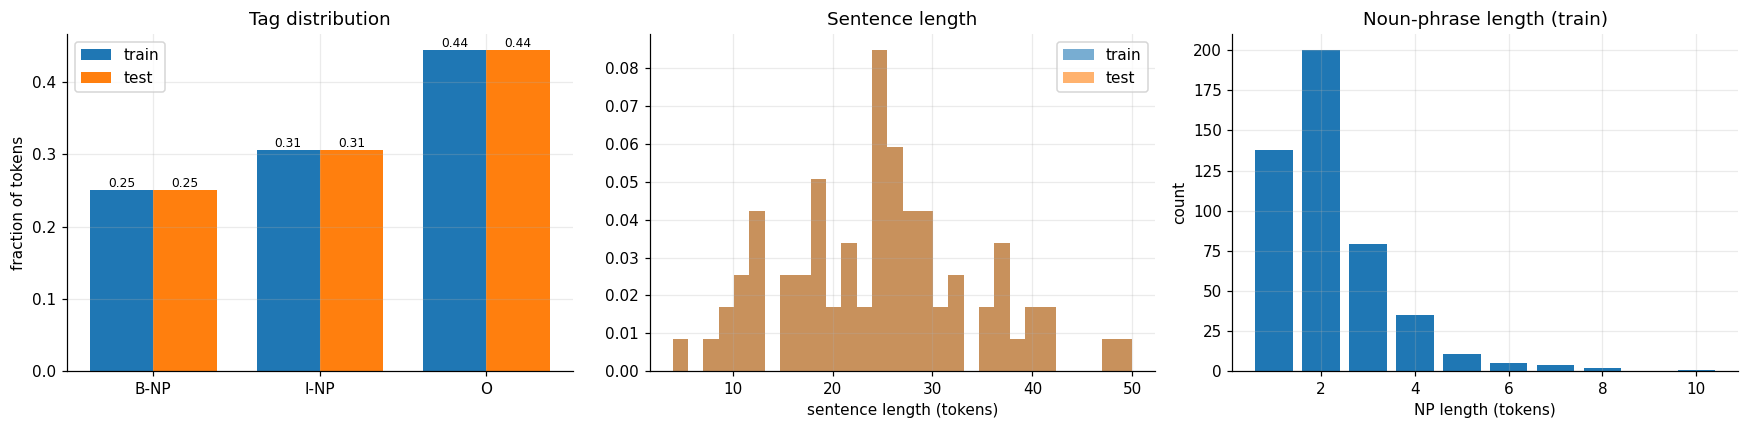

Mean NP length: 2.22 tokens | mean sentence length: 24.6


In [10]:
TAGS = ['B-NP', 'I-NP', 'O']
tag_counts_tr = Counter(t for _,ts in train for t in ts)
tag_counts_te = Counter(t for _,ts in test  for t in ts)

fig, ax = plt.subplots(1, 3, figsize=(16, 4))

# (a) tag distribution
x = np.arange(len(TAGS)); wd = .38
tr = np.array([tag_counts_tr[t] for t in TAGS]); te = np.array([tag_counts_te[t] for t in TAGS])
ax[0].bar(x-wd/2, tr/tr.sum(), wd, label='train'); ax[0].bar(x+wd/2, te/te.sum(), wd, label='test')
ax[0].set_xticks(x); ax[0].set_xticklabels(TAGS); ax[0].set_ylabel('fraction of tokens'); ax[0].set_title('Tag distribution'); ax[0].legend()
for i,(a,b) in enumerate(zip(tr/tr.sum(), te/te.sum())):
    ax[0].text(i-wd/2, a+.005, f'{a:.2f}', ha='center', fontsize=8); ax[0].text(i+wd/2, b+.005, f'{b:.2f}', ha='center', fontsize=8)

# (b) sentence length
ax[1].hist([len(w) for w,_ in train], bins=30, alpha=.6, density=True, label='train')
ax[1].hist([len(w) for w,_ in test],  bins=30, alpha=.6, density=True, label='test')
ax[1].set_xlabel('sentence length (tokens)'); ax[1].set_title('Sentence length'); ax[1].legend()

# (c) NP chunk length (a chunk = B-NP followed by I-NP*)
def chunk_lengths(sents):
    out = []
    for _, ts in sents:
        cur = 0
        for t in ts:
            if t == 'B-NP':
                if cur: out.append(cur)
                cur = 1
            elif t == 'I-NP' and cur: cur += 1
            else:
                if cur: out.append(cur)
                cur = 0
        if cur: out.append(cur)
    return out
cl = Counter(chunk_lengths(train))
ks = sorted(k for k in cl if k <= 10)
ax[2].bar(ks, [cl[k] for k in ks]); ax[2].set_xlabel('NP length (tokens)'); ax[2].set_ylabel('count'); ax[2].set_title('Noun-phrase length (train)')
plt.tight_layout(); plt.show()
print(f'Mean NP length: {np.mean(chunk_lengths(train)):.2f} tokens | mean sentence length: {np.mean([len(w) for w,_ in train]):.1f}')

In [11]:
# most frequent words per tag
rows = {}
for tag in TAGS:
    c = Counter(w.lower() for ws,ts in train for w,t in zip(ws,ts) if t == tag)
    rows[tag] = [f'{w} ({n})' for w,n in c.most_common(10)]
display(pd.DataFrame(rows, index=range(1, 11)))

# vocabulary overlap
norm = lambda w: w.lower()
vocab_tr = {norm(w) for ws,_ in train for w in ws}
te_tokens = [norm(w) for ws,_ in test for w in ws]
oov_rate = np.mean([w not in vocab_tr for w in te_tokens])
print(f'Train vocabulary: {len(vocab_tr)} word types | test OOV token rate: {oov_rate:.2%}')

# ambiguity: how many words appear with more than one tag?
wt = defaultdict(set)
for ws,ts in train:
    for w,t in zip(ws,ts): wt[norm(w)].add(t)
amb = sum(len(s) > 1 for s in wt.values())
print(f'Ambiguous word types (>1 tag): {amb} / {len(wt)} ({amb/len(wt):.1%})  -> why context (transitions) matters')

,B-NP,I-NP,O
1,the (87),% (15),", (79)"
2,a (31),and (10),. (76)
3,'s (11),rates (10),to (50)
4,an (8),billion (9),in (46)
5,$ (8),", (7)",of (39)
6,sterling (7),exchange (6),for (26)
7,mr. (7),# (6),that (20)
8,freight (7),$ (6),at (19)
9,this (6),year (6),and (18)
10,their (6),green (6),from (16)


Train vocabulary: 702 word types | test OOV token rate: 0.00%
Ambiguous word types (>1 tag): 83 / 702 (11.8%)  -> why context (transitions) matters


## 3. Estimating the HMM (Add-K smoothing)

`build_hmm(sents, K)` returns the log‑probabilities π, A and B. Words are lower‑cased for the emission model (reduces sparsity: "The" / "the").

In [12]:
def build_hmm(sents, K):
    tags = TAGS; T = len(tags); idx = {t:i for i,t in enumerate(tags)}
    start_c = np.zeros(T); trans_c = np.zeros((T,T)); tag_c = np.zeros(T)
    emit_c = defaultdict(lambda: np.zeros(T))
    for ws, ts in sents:
        start_c[idx[ts[0]]] += 1
        for j,(w,t) in enumerate(zip(ws,ts)):
            ti = idx[t]; tag_c[ti] += 1; emit_c[norm(w)][ti] += 1
            if j > 0: trans_c[idx[ts[j-1]], ti] += 1
    V = len(emit_c)
    log_pi = np.log((start_c + K) / (start_c.sum() + K*T))
    log_A  = np.log((trans_c + K) / (trans_c.sum(1, keepdims=True) + K*T))
    den = tag_c + K*(V + 1)
    log_B  = {w: np.log((c + K) / den) for w,c in emit_c.items()}
    return dict(tags=tags, idx=idx, T=T, K=K, V=V, log_pi=log_pi, log_A=log_A, log_B=log_B, log_B_unk=np.log(K/den),
                counts=dict(start=start_c, trans=trans_c, tag=tag_c))

def emission_matrix(words, hmm):
    """(n, T) matrix of log B(w_t | tag)."""
    return np.vstack([hmm['log_B'].get(norm(w), hmm['log_B_unk']) for w in words])

### 3.1 Choosing K on a held-out dev split
Choosing K by looking at the test set would leak information, so we hold out the last 15% of the *training* sentences as a dev set, pick K there, and then re-estimate on the full training set.

In [13]:
def viterbi(words, hmm):
    E = emission_matrix(words, hmm); n, T = E.shape
    delta = np.zeros((n,T)); psi = np.zeros((n,T), dtype=int)
    delta[0] = hmm['log_pi'] + E[0]
    for t in range(1, n):
        scores = delta[t-1][:,None] + hmm['log_A']          # scores[i,j] = delta[t-1,i] + log A[i,j]
        psi[t] = scores.argmax(0)
        delta[t] = scores.max(0) + E[t]
    path = [int(delta[-1].argmax())]
    for t in range(n-1, 0, -1): path.append(int(psi[t, path[-1]]))
    path = path[::-1]
    return [hmm['tags'][i] for i in path], delta, psi

def forward(words, hmm):
    E = emission_matrix(words, hmm); n, T = E.shape
    la = np.zeros((n,T)); la[0] = hmm['log_pi'] + E[0]
    for t in range(1, n):
        la[t] = logsumexp(la[t-1][:,None] + hmm['log_A'], axis=0) + E[t]
    return la, logsumexp(la[-1])

split = int(.85*len(train)); sub_train, dev = train[:split], train[split:]
Ks = [10, 3, 1, .3, .1, .03, .01, .003, .001, 1e-4]
dev_rows = []
for K in Ks:
    h = build_hmm(sub_train, K)
    pred = [viterbi(ws, h)[0] for ws,_ in dev]; gold = [ts for _,ts in dev]
    ll = np.mean([forward(ws, h)[1] for ws,_ in dev])
    dev_rows.append((K, f1_score(gold, pred), accuracy_score(gold, pred), ll))
dev_df = pd.DataFrame(dev_rows, columns=['K','dev_F1','dev_token_acc','dev_mean_logP'])
display(dev_df.style.format({'dev_F1':'{:.4f}','dev_token_acc':'{:.4f}','dev_mean_logP':'{:.1f}'}).highlight_max(subset=['dev_F1'], color='#c8e6c9'))
BEST_K = float(dev_df.loc[dev_df.dev_F1.idxmax(), 'K'])
print('Selected K =', BEST_K)

,K,dev_F1,dev_token_acc,dev_mean_logP
0,10.000000,0.3969,0.7072,-135.5
1,3.000000,0.4651,0.7643,-131.7
2,1.000000,0.5649,0.8137,-130.1
3,0.300000,0.6260,0.8251,-132.5
4,0.100000,0.5954,0.8023,-137.9
5,0.030000,0.5909,0.7985,-145.4
6,0.010000,0.5986,0.7985,-152.9
7,0.003000,0.5986,0.7985,-161.1
8,0.001000,0.5986,0.7985,-168.7
9,0.000100,0.5986,0.7985,-184.7


Selected K = 0.3


|T|=3  |V|=702  K=0.3


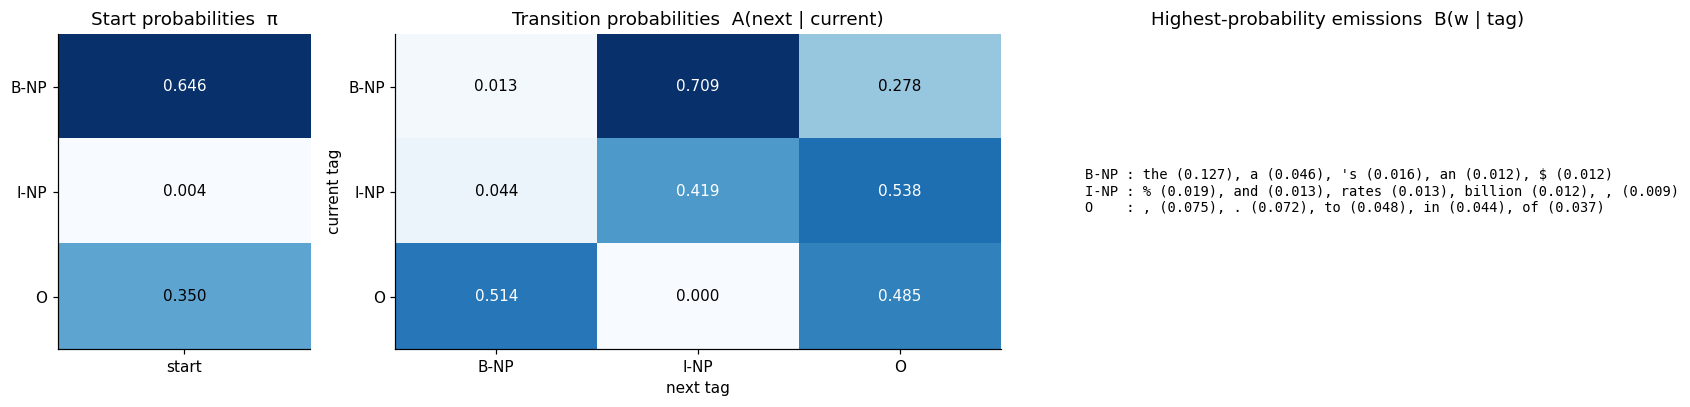

Note: P(I-NP | O) is only smoothing mass -- an NP cannot begin with I-NP, so the data never produces it. Add-K keeps it non-zero but tiny.
Row sums of A: [1. 1. 1.] | sum of π: 1.0


In [14]:
# final model on the FULL training set
K = BEST_K
hmm = build_hmm(train, K)
print(f"|T|={hmm['T']}  |V|={hmm['V']}  K={K}")

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8), gridspec_kw={'width_ratios':[1,2.4,2]})

def heat(a, mat, xt, yt, title, fmt='{:.3f}', cmap='Blues'):
    im = a.imshow(mat, cmap=cmap, aspect='auto'); a.grid(False)
    a.set_xticks(range(len(xt))); a.set_xticklabels(xt); a.set_yticks(range(len(yt))); a.set_yticklabels(yt); a.set_title(title)
    for i in range(mat.shape[0]):
        for j in range(mat.shape[1]):
            a.text(j, i, fmt.format(mat[i,j]), ha='center', va='center', color='white' if mat[i,j] > mat.max()*.55 else 'black', fontsize=10)
    return im

heat(ax[0], np.exp(hmm['log_pi'])[:,None], ['start'], TAGS, 'Start probabilities  π')
heat(ax[1], np.exp(hmm['log_A']), TAGS, TAGS, 'Transition probabilities  A(next | current)')
ax[1].set_xlabel('next tag'); ax[1].set_ylabel('current tag')

# most informative emissions: top-8 words per tag by B(w|t)
top = {t: sorted(hmm['log_B'], key=lambda w: -hmm['log_B'][w][i])[:8] for i,t in enumerate(TAGS)}
ax[2].axis('off'); ax[2].set_title('Highest-probability emissions  B(w | tag)')
txt = '\n'.join(f"{t:5s}: " + ', '.join(f"{w} ({np.exp(hmm['log_B'][w][i]):.3f})" for w in top[t][:5]) for i,t in enumerate(TAGS))
ax[2].text(0, .5, txt, va='center', family='monospace', fontsize=9)
plt.tight_layout(); plt.show()
print('Note: P(I-NP | O) is only smoothing mass -- an NP cannot begin with I-NP, so the data never produces it. Add-K keeps it non-zero but tiny.')
print('Row sums of A:', np.exp(hmm['log_A']).sum(1).round(6), '| sum of π:', np.exp(hmm['log_pi']).sum().round(6))

## 4. Forward algorithm — P(sentence)

### 4.1 Worked example on a short test sentence
We show the full α trellis (log‑space), then **verify** the result by brute force: enumerate all 3ⁿ tag sequences, sum their joint probabilities, and compare with the forward value.

In [15]:
lens = np.array([len(w) for w,_ in test])
ex_i = int(np.where(lens >= 7)[0][np.argmin(lens[lens >= 7])])      # shortest test sentence with >= 7 tokens
ex_words, ex_gold = test[ex_i]
print('Example sentence:', ' '.join(ex_words), f'  (n={len(ex_words)})')

log_alpha, logP = forward(ex_words, hmm)
alpha_df = pd.DataFrame(log_alpha.T, index=TAGS, columns=[f'{i+1}:{w}' for i,w in enumerate(ex_words)])
print('\nlog α_t(tag)  (rows = tags, columns = positions):')
display(alpha_df.round(2))
print(f'log P(sentence) = logsumexp(α_n) = {logP:.4f}   ->   P = {math.exp(logP):.4e}')

# brute-force check
E = emission_matrix(ex_words, hmm); n = len(ex_words)
def joint_logp(seq):
    s = hmm['log_pi'][seq[0]] + E[0, seq[0]]
    for t in range(1, n): s += hmm['log_A'][seq[t-1], seq[t]] + E[t, seq[t]]
    return s
all_paths = list(itertools.product(range(hmm['T']), repeat=n))
brute = logsumexp([joint_logp(p) for p in all_paths])
print(f'Brute force over {len(all_paths):,} tag sequences: log P = {brute:.4f}   |difference| = {abs(brute-logP):.2e}   OK' if abs(brute-logP) < 1e-8 else 'MISMATCH!')

Example sentence: A.P. Green currently has 2,664,098 shares outstanding .   (n=8)

log α_t(tag)  (rows = tags, columns = positions):


,1:A.P.,2:Green,3:currently,4:has,"5:2,664,098",6:shares,7:outstanding,8:.
B-NP,-5.51,-16.89,-21.39,-26.37,-30.12,-40.28,-46.46,-51.60
I-NP,-11.40,-10.68,-19.43,-27.96,-34.46,-35.94,-44.66,-53.16
O,-9.21,-14.91,-17.99,-23.19,-32.04,-39.32,-43.22,-46.32


log P(sentence) = logsumexp(α_n) = -46.3089   ->   P = 7.7323e-21
Brute force over 6,561 tag sequences: log P = -46.3089   |difference| = 0.00e+00   OK


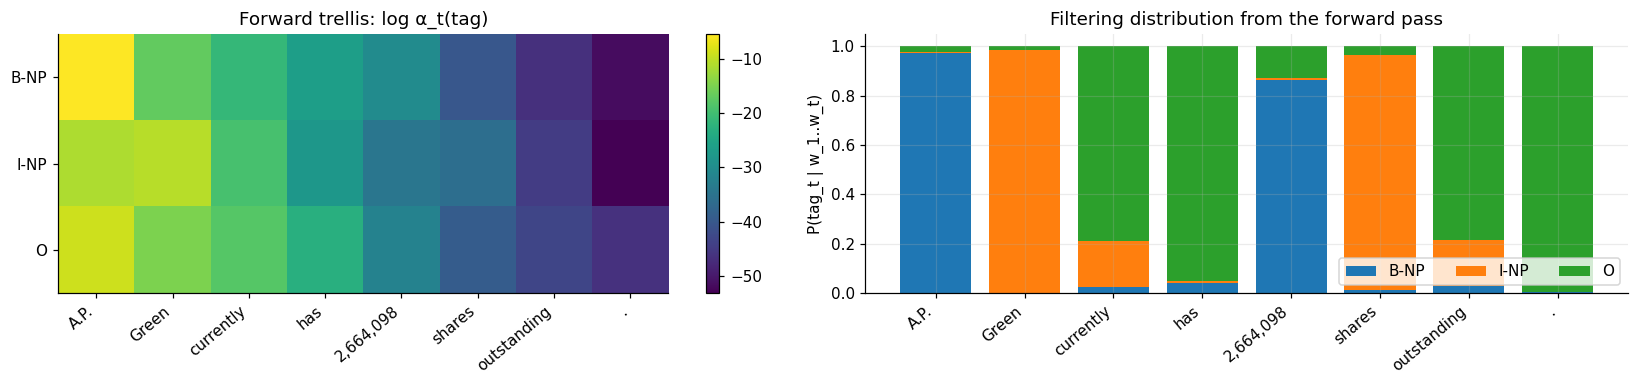

In [16]:
fig, ax = plt.subplots(1, 2, figsize=(15, 3.6))
im = ax[0].imshow(log_alpha.T, cmap='viridis', aspect='auto'); ax[0].grid(False)
ax[0].set_yticks(range(3)); ax[0].set_yticklabels(TAGS); ax[0].set_xticks(range(n)); ax[0].set_xticklabels(ex_words, rotation=40, ha='right')
ax[0].set_title('Forward trellis: log α_t(tag)'); plt.colorbar(im, ax=ax[0])

# posterior-style view: normalised alpha = P(tag_t | w_1..w_t)  (filtering distribution)
filt = np.exp(log_alpha - logsumexp(log_alpha, axis=1, keepdims=True))
bottom = np.zeros(n)
for i,t in enumerate(TAGS):
    ax[1].bar(range(n), filt[:,i], bottom=bottom, label=t); bottom += filt[:,i]
ax[1].set_xticks(range(n)); ax[1].set_xticklabels(ex_words, rotation=40, ha='right'); ax[1].set_ylabel('P(tag_t | w_1..w_t)')
ax[1].set_title('Filtering distribution from the forward pass'); ax[1].legend(ncol=3, loc='lower right')
plt.tight_layout(); plt.show()

### 4.2 Probability of every test sentence

In [17]:
fwd_logp = np.array([forward(ws, hmm)[1] for ws,_ in test])
fwd_df = pd.DataFrame({'sent_id': np.arange(1, len(test)+1),
                       'length': [len(ws) for ws,_ in test],
                       'log_P': fwd_logp,
                       'P': np.exp(fwd_logp),
                       'log_P_per_token': fwd_logp / np.array([len(ws) for ws,_ in test]),
                       'sentence': [' '.join(ws) for ws,_ in test]})
display(fwd_df.assign(P=fwd_df.P.map('{:.3e}'.format), log_P=fwd_df.log_P.round(3), log_P_per_token=fwd_df.log_P_per_token.round(3),
                     sentence=fwd_df.sentence.str.slice(0, 70)).head(15))
print(f'... {len(fwd_df)} sentences in total; full table is in `fwd_df` and saved to forward_probabilities.csv')
fwd_df.to_csv('forward_probabilities.csv', index=False)

,sent_id,length,log_P,P,log_P_per_token,sentence
0,1,37,-207.228,1.005e-90,-5.601,Confidence in the pound is widely expected to take another sharp dive
1,2,27,-149.325,1.409e-65,-5.531,Chancellor of the Exchequer Nigel Lawson 's restated commitment to a f
2,3,29,-170.792,6.702e-75,-5.889,But analysts reckon underlying support for sterling has been eroded by
3,4,36,-191.391,7.582e-84,-5.316,This has increased the risk of the government being forced to increase
4,5,31,-169.434,2.606e-74,-5.466,`` The risks for sterling of a bad trade figure are very heavily on th
5,6,36,-198.899,4.160e-87,-5.525,"`` If there is another bad trade number , there could be an awful lot"
6,7,39,-213.364,2.174e-93,-5.471,"Forecasts for the trade figures range widely , but few economists expe"
7,8,25,-134.989,2.372e-59,-5.400,The August deficit and the # 2.2 billion gap registered in July are to
8,9,28,-164.122,5.280e-72,-5.862,"Sanjay Joshi , European economist at Baring Brothers & Co. , said ther"
9,10,24,-137.537,1.855e-60,-5.731,"At the same time , he remains fairly pessimistic about the outlook for"


... 77 sentences in total; full table is in `fwd_df` and saved to forward_probabilities.csv


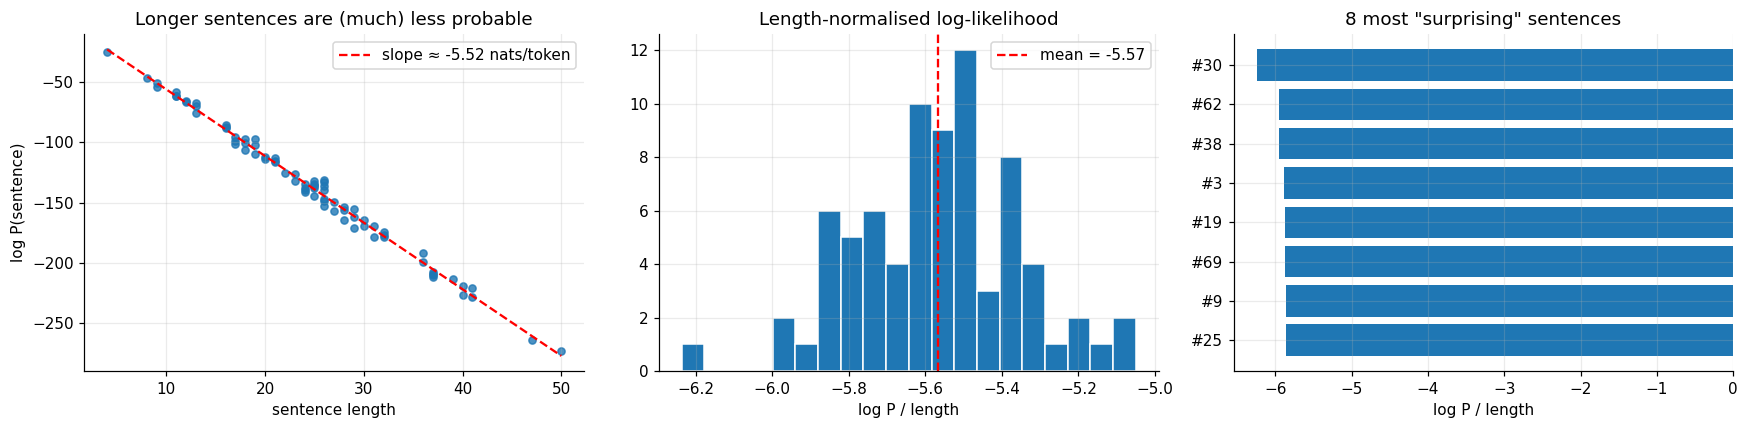

Most surprising sentence: Friday 's Market Activity


In [18]:
fig, ax = plt.subplots(1, 3, figsize=(16, 4))
ax[0].scatter(fwd_df.length, fwd_df.log_P, s=22, alpha=.8)
b = np.polyfit(fwd_df.length, fwd_df.log_P, 1); xs = np.linspace(fwd_df.length.min(), fwd_df.length.max(), 50)
ax[0].plot(xs, np.polyval(b, xs), 'r--', label=f'slope ≈ {b[0]:.2f} nats/token'); ax[0].legend()
ax[0].set_xlabel('sentence length'); ax[0].set_ylabel('log P(sentence)'); ax[0].set_title('Longer sentences are (much) less probable')

ax[1].hist(fwd_df.log_P_per_token, bins=20, edgecolor='white'); ax[1].set_xlabel('log P / length'); ax[1].set_title('Length-normalised log-likelihood')
ax[1].axvline(fwd_df.log_P_per_token.mean(), color='r', ls='--', label=f'mean = {fwd_df.log_P_per_token.mean():.2f}'); ax[1].legend()

# which sentences does the model find 'surprising'? (lowest per-token likelihood)
worst = fwd_df.nsmallest(8, 'log_P_per_token').iloc[::-1]
ax[2].barh([f'#{i}' for i in worst.sent_id], worst.log_P_per_token); ax[2].set_title('8 most "surprising" sentences'); ax[2].set_xlabel('log P / length')
plt.tight_layout(); plt.show()
print('Most surprising sentence:', fwd_df.loc[fwd_df.log_P_per_token.idxmin(), 'sentence'][:150])

## 5. Viterbi decoding

### 5.1 Worked example
Same short sentence: the trellis of δ_t(tag) = max‑log‑probability of any path ending in `tag` at position t, with the back‑traced best path outlined.

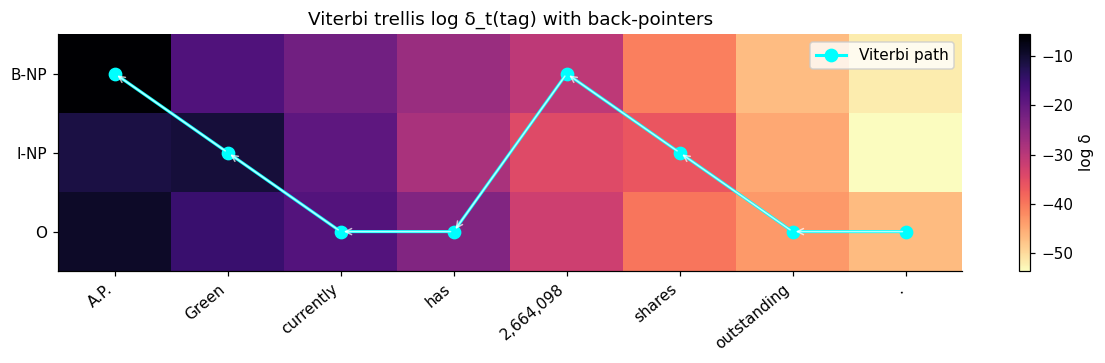

word     A.P.  Green  currently  has  2,664,098  shares  outstanding  .
gold     B-NP   I-NP          O    O       B-NP    I-NP            O  O
viterbi  B-NP   I-NP          O    O       B-NP    I-NP            O  O
match       ✓      ✓          ✓    ✓          ✓       ✓            ✓  ✓

log P(best path, words) = -46.8748 | log P(words) [forward] = -46.3089 | best path carries 56.8% of the total probability mass
Verified: Viterbi score equals the brute-force maximum over all 6,561 sequences.


In [19]:
path, delta, psi = viterbi(ex_words, hmm)
pidx = [hmm['idx'][t] for t in path]
fig, ax = plt.subplots(figsize=(11, 3.4))
im = ax.imshow(delta.T, cmap='magma_r', aspect='auto'); ax.grid(False); plt.colorbar(im, ax=ax, label='log δ')
ax.set_yticks(range(3)); ax.set_yticklabels(TAGS); ax.set_xticks(range(n)); ax.set_xticklabels(ex_words, rotation=40, ha='right')
ax.plot(range(n), pidx, 'o-', color='cyan', lw=2, ms=8, label='Viterbi path')
for t in range(1, n):   # back-pointers
    ax.annotate('', xy=(t-1, psi[t, pidx[t]]), xytext=(t, pidx[t]), arrowprops=dict(arrowstyle='->', color='white', lw=1, alpha=.7))
ax.legend(loc='upper right'); ax.set_title('Viterbi trellis log δ_t(tag) with back-pointers'); plt.tight_layout(); plt.show()

print(pd.DataFrame({'word': ex_words, 'gold': ex_gold, 'viterbi': path, 'match': ['✓' if a==b else '✗' for a,b in zip(ex_gold, path)]}).T.to_string(header=False))
best_lp = delta[-1].max()
print(f'\nlog P(best path, words) = {best_lp:.4f} | log P(words) [forward] = {logP:.4f} | best path carries {math.exp(best_lp-logP):.1%} of the total probability mass')
assert abs(best_lp - max(joint_logp(p) for p in all_paths)) < 1e-8, 'Viterbi != brute-force argmax'
print('Verified: Viterbi score equals the brute-force maximum over all', f'{len(all_paths):,}', 'sequences.')

### 5.2 Decode all test sentences

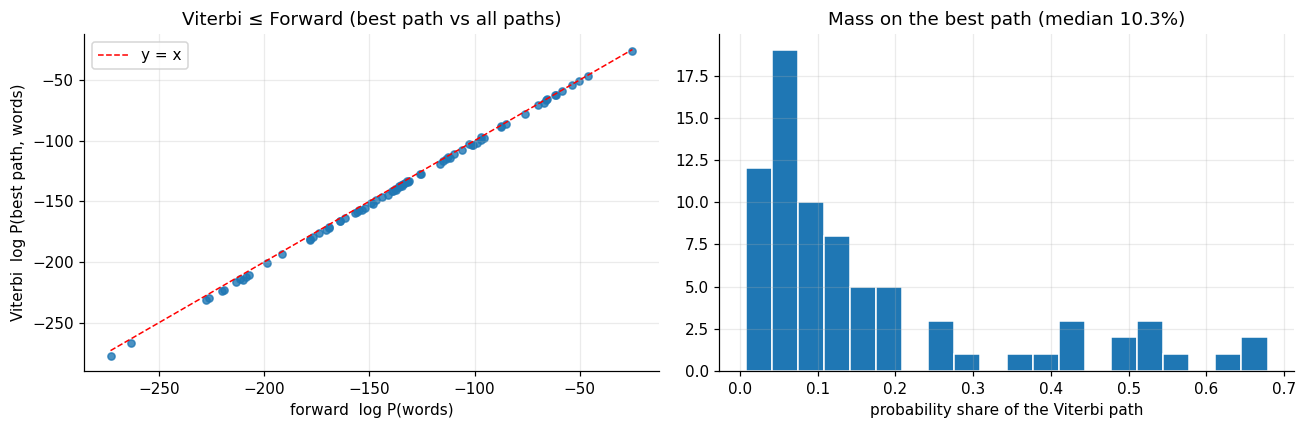

In [20]:
y_true = [ts for _,ts in test]
decoded = [viterbi(ws, hmm) for ws,_ in test]
y_pred = [d[0] for d in decoded]
vit_logp = np.array([d[1][-1].max() for d in decoded])

fig, ax = plt.subplots(1, 2, figsize=(12, 4))
ax[0].scatter(fwd_logp, vit_logp, s=22, alpha=.8); lo, hi = fwd_logp.min(), fwd_logp.max()
ax[0].plot([lo,hi],[lo,hi],'r--',lw=1,label='y = x'); ax[0].set_xlabel('forward  log P(words)'); ax[0].set_ylabel('Viterbi  log P(best path, words)')
ax[0].set_title('Viterbi ≤ Forward (best path vs all paths)'); ax[0].legend()
share = np.exp(vit_logp - fwd_logp)
ax[1].hist(share, bins=20, edgecolor='white'); ax[1].set_xlabel('probability share of the Viterbi path'); ax[1].set_title(f'Mass on the best path (median {np.median(share):.1%})')
plt.tight_layout(); plt.show()
assert np.all(vit_logp <= fwd_logp + 1e-9)

## 6. Evaluation (seqeval)

`seqeval` works at the **chunk (entity) level**: a predicted NP counts as correct only if its boundaries are exactly right. We additionally report token‑level metrics and a confusion matrix.

In [21]:
print(classification_report(y_true, y_pred, digits=4))
P, R, F = precision_score(y_true,y_pred), recall_score(y_true,y_pred), f1_score(y_true,y_pred)
print(f'Chunk-level  precision={P:.4f}  recall={R:.4f}  F1={F:.4f}   |   token accuracy={accuracy_score(y_true,y_pred):.4f}')

              precision    recall  f1-score   support

          NP     0.8863    0.8863    0.8863       475

   micro avg     0.8863    0.8863    0.8863       475
   macro avg     0.8863    0.8863    0.8863       475
weighted avg     0.8863    0.8863    0.8863       475

Chunk-level  precision=0.8863  recall=0.8863  F1=0.8863   |   token accuracy=0.9599


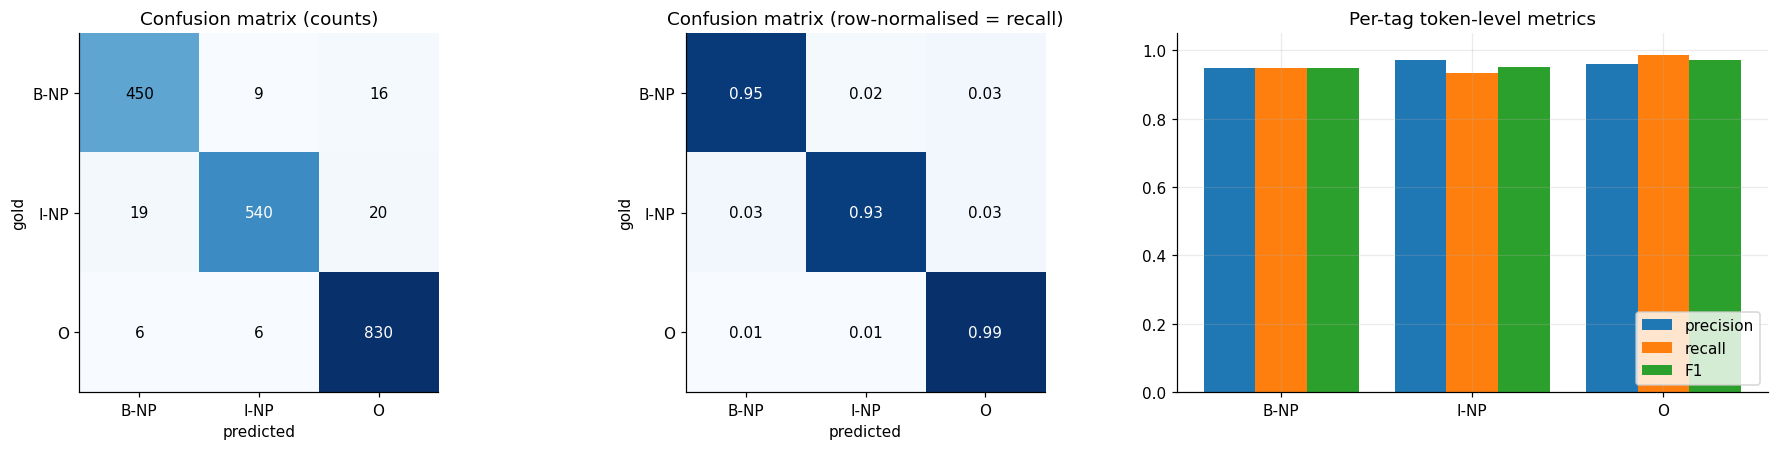

,precision,recall,F1,support
B-NP,0.9474,0.9474,0.9474,475
I-NP,0.9730,0.9326,0.9524,579
O,0.9584,0.9857,0.9719,842


In [22]:
flat_t = [t for ts in y_true for t in ts]; flat_p = [t for ts in y_pred for t in ts]
cm = pd.crosstab(pd.Series(flat_t, name='gold'), pd.Series(flat_p, name='predicted')).reindex(index=TAGS, columns=TAGS, fill_value=0)
cmn = cm.div(cm.sum(axis=1), axis=0)

# per-tag token-level precision/recall/F1
tp = np.diag(cm.values); prec = tp/cm.values.sum(0); rec = tp/cm.values.sum(1); f1 = 2*prec*rec/(prec+rec)

fig, ax = plt.subplots(1, 3, figsize=(17, 4.2))
for a, m, title, fmt in [(ax[0], cm.values, 'Confusion matrix (counts)', '{:.0f}'), (ax[1], cmn.values, 'Confusion matrix (row-normalised = recall)', '{:.2f}')]:
    a.imshow(m, cmap='Blues'); a.grid(False); a.set_title(title)
    a.set_xticks(range(3)); a.set_xticklabels(TAGS); a.set_yticks(range(3)); a.set_yticklabels(TAGS); a.set_xlabel('predicted'); a.set_ylabel('gold')
    for i in range(3):
        for j in range(3): a.text(j, i, fmt.format(m[i,j]), ha='center', va='center', color='white' if m[i,j] > m.max()*.55 else 'black')
x = np.arange(3); wd = .27
ax[2].bar(x-wd, prec, wd, label='precision'); ax[2].bar(x, rec, wd, label='recall'); ax[2].bar(x+wd, f1, wd, label='F1')
ax[2].set_xticks(x); ax[2].set_xticklabels(TAGS); ax[2].set_ylim(0, 1.05); ax[2].set_title('Per-tag token-level metrics'); ax[2].legend(loc='lower right')
plt.tight_layout(); plt.show()
display(pd.DataFrame({'precision':prec,'recall':rec,'F1':f1,'support':cm.sum(axis=1).values}, index=TAGS).round(4))

ValueError: Length mismatch: Expected axis has 1 elements, new values have 2 elements

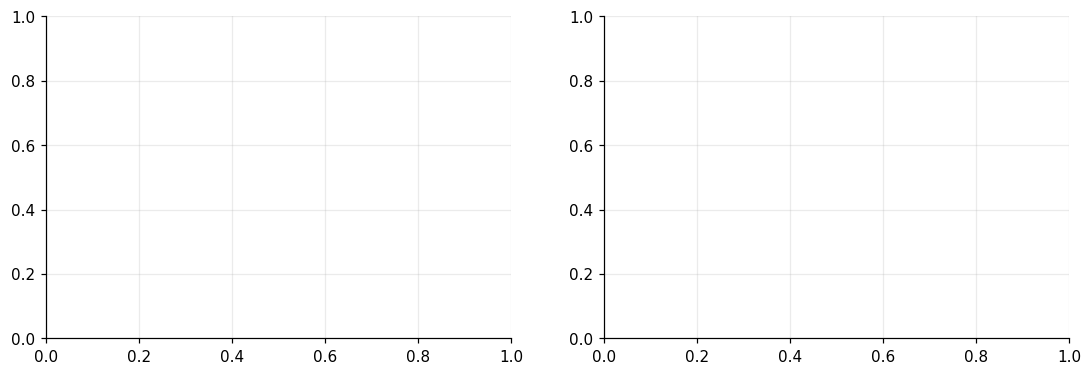

In [23]:
# Where does performance break down?  (a) OOV vs known words   (b) sentence length
rows = []
for (ws, gold), pred in zip(test, y_pred):
    for w,g,p in zip(ws, gold, pred): rows.append((len(ws), norm(w) not in hmm['log_B'], g, p))
tok = pd.DataFrame(rows, columns=['sent_len','oov','gold','pred']); tok['ok'] = tok.gold == tok.pred

fig, ax = plt.subplots(1, 2, figsize=(12, 3.8))
g = tok.groupby('oov').ok.agg(['mean','count']); g.index = ['known word','OOV word']
ax[0].bar(g.index, g['mean'], color=['tab:blue','tab:orange']); ax[0].set_ylim(0,1); ax[0].set_title('Token accuracy: known vs unseen words')
for i,(m,c) in enumerate(zip(g['mean'], g['count'])): ax[0].text(i, m+.02, f'{m:.2f}\n(n={c})', ha='center')
bins = pd.cut(tok.sent_len, [0,10,15,20,25,30,100]); g2 = tok.groupby(bins, observed=True).ok.agg(['mean','count'])
ax[1].bar([str(i) for i in g2.index], g2['mean'], color='tab:green'); ax[1].set_ylim(0,1); ax[1].set_xlabel('sentence length bucket'); ax[1].set_title('Token accuracy by sentence length')
for i,(m,c) in enumerate(zip(g2['mean'], g2['count'])): ax[1].text(i, m+.02, f'{m:.2f}', ha='center')
plt.tight_layout(); plt.show()
print(f'OOV share of test tokens: {tok.oov.mean():.1%}')

# sequences that violate BIO syntax (I-NP directly after O / at sentence start)
def bio_violations(seqs):
    return sum(1 for s in seqs for i,t in enumerate(s) if t == 'I-NP' and (i == 0 or s[i-1] == 'O'))
print('BIO-invalid I-NP in gold:', bio_violations(y_true), '| in Viterbi output:', bio_violations(y_pred), '(the HMM learned that O → I-NP is near-impossible)')

### 6.1 Error analysis

In [24]:
errs = Counter(); err_ctx = defaultdict(Counter)
for (ws, gold), pred in zip(test, y_pred):
    for w,g,p in zip(ws, gold, pred):
        if g != p: errs[(norm(w))] += 1; err_ctx[norm(w)][(g,p)] += 1
print('Words causing the most token errors:')
display(pd.DataFrame([(w, n, ', '.join(f'{g}→{p}: {c}' for (g,p),c in err_ctx[w].most_common(2)), sum(norm(x)==w for ws,_ in train for x in ws)) for w,n in errs.most_common(12)],
                     columns=['word','#errors','(gold→pred)','train freq']))

# sentences with the lowest token accuracy
sent_acc = [(np.mean([a==b for a,b in zip(g,p)]), i) for i,(g,p) in enumerate(zip(y_true, y_pred))]
print('\nThree worst sentences (gold vs predicted; mismatches in [brackets]):')
for acc,i in sorted(sent_acc)[:3]:
    ws = test[i][0]
    print(f'\n#{i+1}  token acc = {acc:.2f}')
    print('  ', ' '.join(f'{w}/{p}' if p==g else f'[{w}: gold {g}, pred {p}]' for w,g,p in zip(ws, y_true[i], y_pred[i])))

Words causing the most token errors:


,word,#errors,(gold→pred),train freq
0,",",6,I-NP→O: 6,86
1,and,5,"O→I-NP: 3, I-NP→O: 2",28
2,this,3,"I-NP→B-NP: 2, B-NP→I-NP: 1",8
3,that,3,B-NP→O: 3,24
4,august,2,"I-NP→O: 1, B-NP→O: 1",4
5,firm,2,"I-NP→O: 1, O→I-NP: 1",2
6,increase,2,I-NP→O: 2,5
7,lawson,2,I-NP→O: 2,4
8,higher,2,"O→B-NP: 1, B-NP→O: 1",4
9,'s,2,B-NP→O: 2,14



Three worst sentences (gold vs predicted; mismatches in [brackets]):

#30  token acc = 0.50
   Friday/B-NP ['s: gold B-NP, pred O] [Market: gold I-NP, pred B-NP] Activity/I-NP

#13  token acc = 0.77
   Combined/O with/O [at: gold B-NP, pred O] [least: gold I-NP, pred O] [some: gold I-NP, pred B-NP] rebound/I-NP in/O exports/B-NP after/O [August: gold B-NP, pred O] 's/B-NP unexpected/I-NP decline/I-NP ,/O the/B-NP deficit/I-NP could/O narrow/O to/O [as: gold B-NP, pred O] [little: gold I-NP, pred B-NP] as/I-NP #/I-NP 1.3/I-NP billion/I-NP ./O

#61  token acc = 0.83
   The/B-NP deregulation/I-NP of/O railroads/B-NP [and: gold I-NP, pred O] [trucking: gold I-NP, pred B-NP] companies/I-NP [that: gold B-NP, pred O] began/O in/O 1980/B-NP enabled/O shippers/B-NP to/O bargain/O for/O transportation/B-NP ./O


## 7. Sensitivity to the smoothing constant K

Dev‑set curve (used for model selection) alongside the test curve (for information only — not used to choose K).

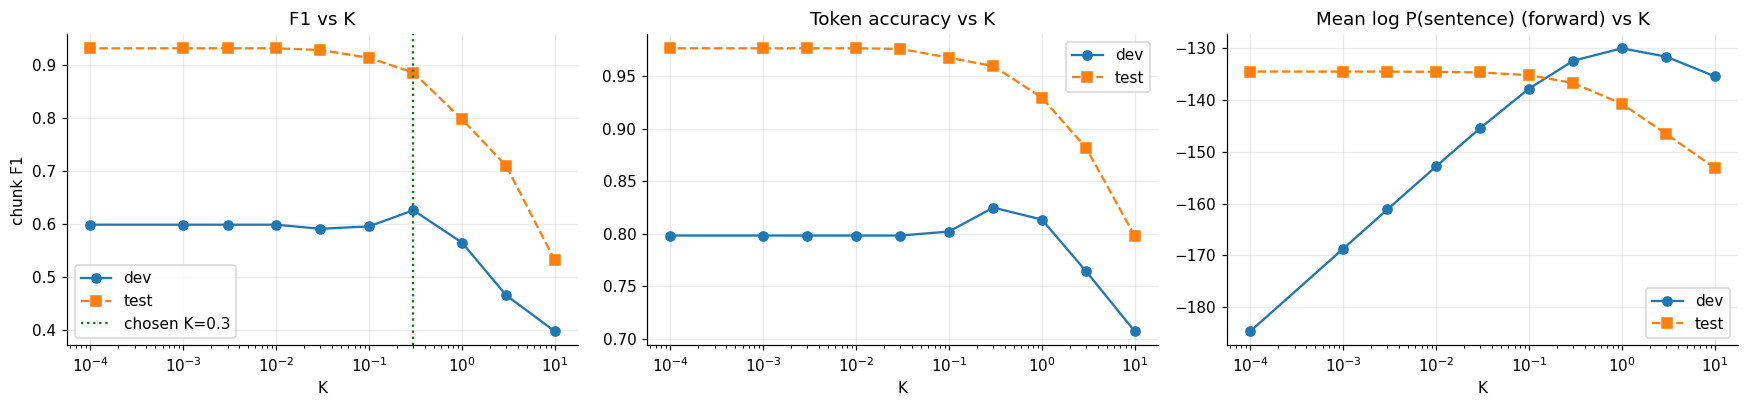

,K,test_F1,test_token_acc,test_mean_logP
0,10.0000,0.5310,0.7980,-153.1503
1,3.0000,0.7097,0.8819,-146.5592
2,1.0000,0.7983,0.9299,-140.7749
3,0.3000,0.8863,0.9599,-136.7650
4,0.1000,0.9142,0.9678,-135.2386
5,0.0300,0.9290,0.9763,-134.7165
6,0.0100,0.9322,0.9768,-134.5926
7,0.0030,0.9322,0.9768,-134.5575
8,0.0010,0.9322,0.9768,-134.5490
9,0.0001,0.9322,0.9768,-134.5455


In [25]:
test_rows = []
for Kv in Ks:
    h = build_hmm(train, Kv)
    pr = [viterbi(ws, h)[0] for ws,_ in test]
    test_rows.append((Kv, f1_score(y_true, pr), accuracy_score(y_true, pr), np.mean([forward(ws, h)[1] for ws,_ in test])))
test_df = pd.DataFrame(test_rows, columns=['K','test_F1','test_token_acc','test_mean_logP'])

fig, ax = plt.subplots(1, 3, figsize=(16, 3.8))
ax[0].semilogx(dev_df.K, dev_df.dev_F1, 'o-', label='dev'); ax[0].semilogx(test_df.K, test_df.test_F1, 's--', label='test')
ax[0].axvline(BEST_K, color='g', ls=':', label=f'chosen K={BEST_K:g}'); ax[0].set_xlabel('K'); ax[0].set_ylabel('chunk F1'); ax[0].set_title('F1 vs K'); ax[0].legend()
ax[1].semilogx(dev_df.K, dev_df.dev_token_acc, 'o-', label='dev'); ax[1].semilogx(test_df.K, test_df.test_token_acc, 's--', label='test')
ax[1].set_xlabel('K'); ax[1].set_title('Token accuracy vs K'); ax[1].legend()
ax[2].semilogx(dev_df.K, dev_df.dev_mean_logP, 'o-', label='dev'); ax[2].semilogx(test_df.K, test_df.test_mean_logP, 's--', label='test')
ax[2].set_xlabel('K'); ax[2].set_title('Mean log P(sentence) (forward) vs K'); ax[2].legend()
plt.tight_layout(); plt.show()
display(test_df.round(4))

## 8. Save results

In [26]:
with open('viterbi_predictions.txt', 'w', encoding='utf-8') as f:
    for (ws, gold), pred in zip(test, y_pred):
        for w,g,p in zip(ws, gold, pred): f.write(f'{w}\t{g}\t{p}\n')
        f.write('\n')
print('Saved: viterbi_predictions.txt (word, gold, predicted) and forward_probabilities.csv')

print(f"""
=========== SUMMARY ===========
Smoothing constant K (chosen on dev): {BEST_K:g}
Forward: mean log P(sentence) = {fwd_logp.mean():.2f}; mean per-token = {np.mean(fwd_df.log_P_per_token):.3f}
Viterbi: chunk P/R/F1 = {P:.3f} / {R:.3f} / {F:.3f};  token accuracy = {accuracy_score(y_true,y_pred):.3f}
""")

Saved: viterbi_predictions.txt (word, gold, predicted) and forward_probabilities.csv

=========== SUMMARY ===========
Smoothing constant K (chosen on dev): 0.3
Forward: mean log P(sentence) = -136.76; mean per-token = -5.566
Viterbi: chunk P/R/F1 = 0.886 / 0.886 / 0.886;  token accuracy = 0.960



### Observations
* **Forward probabilities are tiny** (often 10⁻⁸⁰ or smaller) because they are joint probabilities of whole sentences; log P falls roughly linearly with length (about −7 nats per token on average), so only length‑normalised values are comparable across sentences.
* **Viterbi vs forward**: the best path holds only a fraction of the total mass (45% for the short worked example, see the histogram for the whole test set; it shrinks with sentence length) — many tag sequences are almost as likely, which is typical for a first‑order HMM with a weak (word‑only) emission model.
* **Errors** concentrate on ambiguous words (adverbs, participles, verbs that can start an NP) and on unseen words; `B-NP` vs `I-NP` boundaries are harder than `O`.
* **Possible improvements**: use a second‑order (trigram) HMM, add suffix/capitalisation features for OOV words, or move to a CRF/BiLSTM‑CRF.